In [ ]:
#Loading data (Step 1)
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist


numpy - для работы с массивами
matplotlib - библиотека для отображение изобр-ии. и графиков.


In [ ]:
#Step 2
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
#fashion_mnist.load_data() - загружает готовый набор данных
#train и test data
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


.shape - размер массива

In [ ]:

X_train = X_train[:6000]
y_train = y_train[:6000]

X_test = X_test[:1000]
y_test = y_test[:1000]


#normalization because pixels value has 0-255
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


X_train: (6000, 28, 28)
y_train: (6000,)
X_test: (1000, 28, 28)
y_test: (1000,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


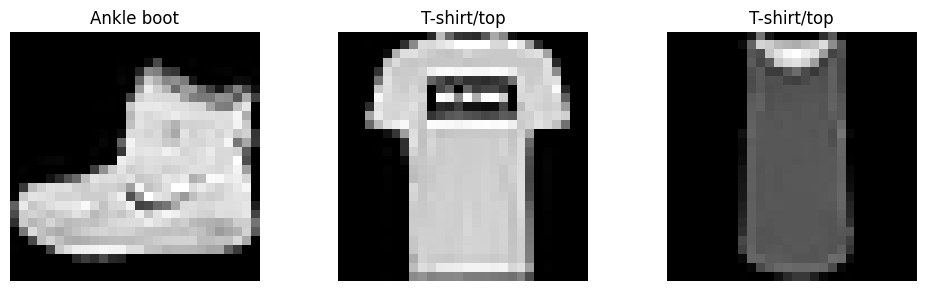

In [ ]:
#Dataset Fashion MNIST has a 10 classes
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]
#создаёт область для рисунка
plt.figure(figsize=(10, 3))

for i in range(3):
  #организует три изображение в одном ряду.
    plt.subplot(1, 3, i + 1)
    #показывает изображение , cmap - отображает его в оттенках серого
    plt.imshow(X_train[i], cmap="gray")
    #получает название класса по метке изображения.
    plt.title(class_names[y_train[i]])
    plt.axis("off")#скрывание координатные оси.

plt.tight_layout()
plt.show()


In [ ]:
#функция которе превращает изображение размером 28х28
#в одномерный массив из 784 значение
def extract_raw_features(images):
  #shape- показывает, сколько элементов находится в каждом измерении.
  #b = np.array([
  #    [10, 20, 30],
  #    [40, 50, 60]
  #
  #    ]) here reshape(2,3)
    return images.reshape(images.shape[0], -1)


raw_features = extract_raw_features(X_train)

print("Raw features shape:", raw_features.shape)


Raw features shape: (6000, 784)


До этого у нас был другой размер массива и тут мы просто изменили его из (28x28) в 784(одномерный)

In [ ]:
#Step 6 : Block Average Features (without saving 784 pixels ) we divide
#blocks into 4x4 blocks and find for each block average average яркость

In [ ]:

def extract_block_features(images):
    n = images.shape[0] #кол:во изображений

    #изменение форму каждого изображени
    #вертикально 7 блоков , горизонтально 7 блоков
    blocks = images.reshape(n, 7, 4, 7, 4)
    #вычисление среднего.
    block_features = blocks.mean(axis=(2, 4))
    #преобразование вектор на 49 признаков
    return block_features.reshape(n, 49)


block_features = extract_block_features(X_train)

print("Block features shape:", block_features.shape)


Block features shape: (6000, 49)


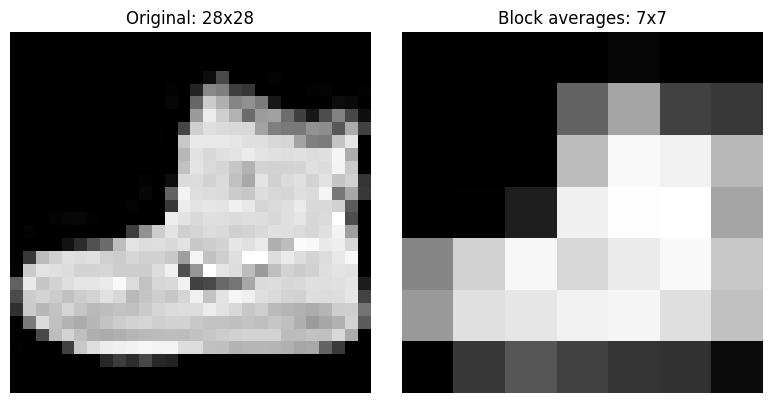

In [ ]:
#Проверка результат визуально :

image_index = 0

original = X_train[image_index]
blocks = extract_block_features(X_train[image_index:image_index + 1])
averaged = blocks.reshape(7, 7)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray")
plt.title("Original: 28x28")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(averaged, cmap="gray")
plt.title("Block averages: 7x7")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#Edge Features

def extract_edge_features(images):
    # 1. Changes between neighboring columns
    dx = np.abs(images[:, :, 1:] - images[:, :, :-1])

    # 2. Changes between neighboring rows
    dy = np.abs(images[:, 1:, :] - images[:, :-1, :])

    # 3. Pad both maps back to 28x28
    dx = np.pad(dx, ((0, 0), (0, 0), (0, 1)))
    dy = np.pad(dy, ((0, 0), (0, 1), (0, 0)))

    # 4. Average edge values inside each 4x4 block
    dx_blocks = extract_block_features(dx)
    dy_blocks = extract_block_features(dy)

    # 5. Join column and row features
    edge_features = np.concatenate(
        [dx_blocks, dy_blocks],
        axis=1
    )

    return edge_features


edge_features = extract_edge_features(X_train)

print("Edge features shape:", edge_features.shape)


Edge features shape: (6000, 98)


In [ ]:

def extract_combined_features(images):
    block_features = extract_block_features(images)
    edge_features = extract_edge_features(images)

    combined_features = np.concatenate(
        [block_features, edge_features],
        axis=1
    )

    return combined_features


combined_features = extract_combined_features(X_train)

print("Combined features shape:", combined_features.shape)


Combined features shape: (6000, 147)


In [ ]:

print("Raw pixels:", raw_features.shape)
print("Block averages:", block_features.shape)
print("Edge measurements:", edge_features.shape)
print("Combined features:", combined_features.shape)


Raw pixels: (6000, 784)
Block averages: (6000, 49)
Edge measurements: (6000, 98)
Combined features: (6000, 147)


Шум возникает из-за плохого освещения

In [ ]:

from sklearn.neural_network import MLPClassifier

# Train the raw-pixel model
raw_model = MLPClassifier(
    hidden_layer_sizes=(32,),
    max_iter=80,
    random_state=42
)

raw_model.fit(raw_features, y_train)

# Train the combined-features model
combined_model = MLPClassifier(
    hidden_layer_sizes=(32,),
    max_iter=80,
    random_state=42
)

combined_model.fit(combined_features, y_train)

print("Both models have been trained.")


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


Both models have been trained.


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
#Task 2 : noise and seed

In [ ]:

noise_level = 0.2
seed = 42

rng = np.random.default_rng(seed)

noise = rng.normal(
    loc=0.0,
    scale=noise_level,
    size=X_test.shape
)

X_test_noisy = np.clip(X_test + noise, 0.0, 1.0)

print("Clean test shape:", X_test.shape)
print("Noisy test shape:", X_test_noisy.shape)
print("Noisy minimum:", X_test_noisy.min())
print("Noisy maximum:", X_test_noisy.max())


Clean test shape: (1000, 28, 28)
Noisy test shape: (1000, 28, 28)
Noisy minimum: 0.0
Noisy maximum: 1.0


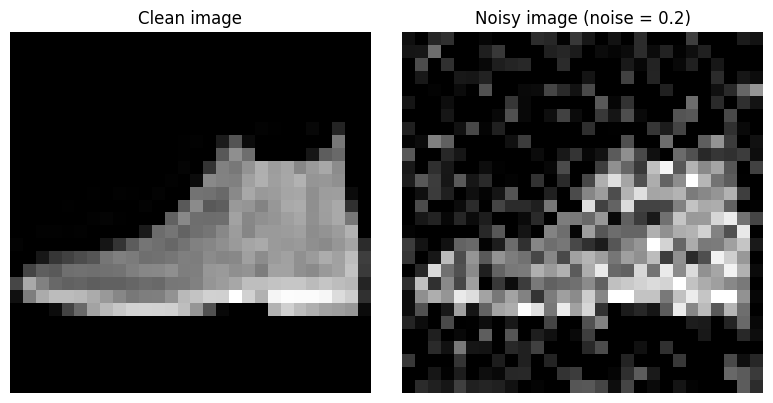

In [ ]:

image_index = 0

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test[image_index], cmap="gray", vmin=0, vmax=1)
plt.title("Clean image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_test_noisy[image_index], cmap="gray", vmin=0, vmax=1)
plt.title("Noisy image (noise = 0.2)")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Raw features
raw_test_clean = extract_raw_features(X_test)
raw_test_noisy = extract_raw_features(X_test_noisy)

# Combined features
combined_test_clean = extract_combined_features(X_test)
combined_test_noisy = extract_combined_features(X_test_noisy)

print("Raw clean:", raw_test_clean.shape)
print("Raw noisy:", raw_test_noisy.shape)
print("Combined clean:", combined_test_clean.shape)
print("Combined noisy:", combined_test_noisy.shape)


Raw clean: (1000, 784)
Raw noisy: (1000, 784)
Combined clean: (1000, 147)
Combined noisy: (1000, 147)


In [ ]:

from sklearn.metrics import accuracy_score

# 1. Raw model on clean test images
raw_pred_clean = raw_model.predict(raw_test_clean)

# 2. Raw model on noisy test images
raw_pred_noisy = raw_model.predict(raw_test_noisy)

# 3. Combined model on clean test images
combined_pred_clean = combined_model.predict(combined_test_clean)

# 4. Combined model on noisy test images
combined_pred_noisy = combined_model.predict(combined_test_noisy)

print("Predictions completed.")


Predictions completed.


In [ ]:

def evaluate_predictions(y_true, y_pred):
    correct = int(np.sum(y_true == y_pred))
    accuracy = accuracy_score(y_true, y_pred)
    return correct, accuracy


raw_clean_correct, raw_clean_acc = evaluate_predictions(
    y_test, raw_pred_clean
)

raw_noisy_correct, raw_noisy_acc = evaluate_predictions(
    y_test, raw_pred_noisy
)

combined_clean_correct, combined_clean_acc = evaluate_predictions(
    y_test, combined_pred_clean
)

combined_noisy_correct, combined_noisy_acc = evaluate_predictions(
    y_test, combined_pred_noisy
)

print(f"Raw clean: {raw_clean_correct}/1000, accuracy = {raw_clean_acc:.2%}")
print(f"Raw noisy: {raw_noisy_correct}/1000, accuracy = {raw_noisy_acc:.2%}")

print(f"Combined clean: {combined_clean_correct}/1000, accuracy = {combined_clean_acc:.2%}")
print(f"Combined noisy: {combined_noisy_correct}/1000, accuracy = {combined_noisy_acc:.2%}")


Raw clean: 845/1000, accuracy = 84.50%
Raw noisy: 763/1000, accuracy = 76.30%
Combined clean: 866/1000, accuracy = 86.60%
Combined noisy: 401/1000, accuracy = 40.10%


In [ ]:

raw_diff = (raw_noisy_acc - raw_clean_acc) * 100
combined_diff = (combined_noisy_acc - combined_clean_acc) * 100

print(f"{'Model input':<20} {'Clean accuracy':>16} {'Noisy accuracy':>16} {'Noisy - clean (pp)':>20}")

print(
    f"{'Raw pixels 784':<20} "
    f"{raw_clean_acc:>15.2%} "
    f"{raw_noisy_acc:>15.2%} "
    f"{raw_diff:>19.2f}"
)

print(
    f"{'Combined 147':<20} "
    f"{combined_clean_acc:>15.2%} "
    f"{combined_noisy_acc:>15.2%} "
    f"{combined_diff:>19.2f}"
)


Model input            Clean accuracy   Noisy accuracy   Noisy - clean (pp)
Raw pixels 784                84.50%          76.30%               -8.20
Combined 147                  86.60%          40.10%              -46.50


In [ ]:

print("Correct predictions:")
print(f"Raw clean: {raw_clean_correct}/1000")
print(f"Raw noisy: {raw_noisy_correct}/1000")
print(f"Combined clean: {combined_clean_correct}/1000")
print(f"Combined noisy: {combined_noisy_correct}/1000")

print("\nFeature shapes:")
print("Raw train:", raw_features.shape)
print("Combined train:", combined_features.shape)
print("Raw clean test:", raw_test_clean.shape)
print("Raw noisy test:", raw_test_noisy.shape)
print("Combined clean test:", combined_test_clean.shape)
print("Combined noisy test:", combined_test_noisy.shape)


Correct predictions:
Raw clean: 845/1000
Raw noisy: 763/1000
Combined clean: 866/1000
Combined noisy: 401/1000

Feature shapes:
Raw train: (6000, 784)
Combined train: (6000, 147)
Raw clean test: (1000, 784)
Raw noisy test: (1000, 784)
Combined clean test: (1000, 147)
Combined noisy test: (1000, 147)
